# Visualising ECG signals
`ECGDrawing` takes a called-and-extracted reader instance and renders the
lead-specific ECG signals on a GridSpec figure with clinical ECG paper scaling.

The layout is fully controlled by a `mapper` dict that maps each lead name to
a `(row_index, col_slice)` position in the GridSpec. Style parameters live in
`ECGStyle`.

In [1]:
import warnings
from tempfile import NamedTemporaryFile

from ecgprocess.process_dicom import ECGDICOMReader
from ecgprocess.utils.config_tools import ConfigParser, DataMap
from ecgprocess.example_data.examples import list_dicom_paths, config_file
from ecgprocess.plot_ecgs import ECGDrawing, ECGStyle
import matplotlib.pyplot as plt

CM_TO_IN: float = 1 / 2.54

dicom_path = list_dicom_paths()['example_dicom_2']

## Canonical ECG image

The standard clinical ECG is printed on a grid of 1 mm small squares and 5 mm
large squares. `ECGDrawing` replicates this using `matplotlib.gridspec.GridSpec`
— one panel per lead — with minor and major grid lines driven by `ECGStyle`'s
`paper_speed` (mm/s) and `mm_per_mv` (mm/mV) fields. Signal traces are allowed
to cross panel borders (`clip_on_trace=False`) replicating the physical paper
look for large deflections.

The caller controls which leads appear and where via a `mapper` dict:
```python
mapper = {
    'I':  (0, slice(0, 1)),   # row 0, column 0
    'II': (0, slice(1, 2)),   # row 0, column 1
    ...
}
```

Steps:
1. Parse a config that maps lead names to DICOM tag paths.
2. Call the reader, then `.extract()` to populate `WaveForms` and `MetaData`.
3. Build a `mapper` from the leads that have data.
4. Pass everything to `ECGDrawing`.

### Step 1: Parse configuration

A config dict maps each lead name to its DICOM tag path. `ConfigParser` turns it into a structured config object and `DataMap` binds it to the expected attribute names.

In [2]:
# Config maps standard 12-lead order for this ECG DICOM format.
# skip_empty=True silently drops leads whose tag paths are absent in the file.
ecg_config = {
    "WaveForms": [
        "I					WaveformData.ECG_Leads_0",
        "II					WaveformData.ECG_Leads_1",
        "III					WaveformData.ECG_Leads_2",
        "aVR					WaveformData.ECG_Leads_3",
        "aVL					WaveformData.ECG_Leads_4",
        "aVF					WaveformData.ECG_Leads_5",
        "V1					WaveformData.ECG_Leads_6",
        "V2					WaveformData.ECG_Leads_7",
        "V3					WaveformData.ECG_Leads_8",
        "V4					WaveformData.ECG_Leads_9",
        "V5					WaveformData.ECG_Leads_10",
        "V6					WaveformData.ECG_Leads_11",
    ],
    "MedianBeats": [
        "I					WaveformData.Median_Beats_0",
        "II					WaveformData.Median_Beats_1",
        "III					WaveformData.Median_Beats_2",
        "aVR					WaveformData.Median_Beats_3",
        "aVL					WaveformData.Median_Beats_4",
        "aVF					WaveformData.Median_Beats_5",
        "V1					WaveformData.Median_Beats_6",
        "V2					WaveformData.Median_Beats_7",
        "V3					WaveformData.Median_Beats_8",
        "V4					WaveformData.Median_Beats_9",
        "V5					WaveformData.Median_Beats_10",
        "V6					WaveformData.Median_Beats_11",
    ],
    "MetaData": [
        "number of leads				Waveform Sequence_0.Number of Waveform Channels",
        "sampling frequency (original)			Waveform Sequence_0.Sampling Frequency",
    ],
}
with NamedTemporaryFile("w") as tmp:
    config_file(path=tmp.name, text=ecg_config)
    cfg = ConfigParser(tmp.name)()
cfg.map(mapper=DataMap())
print(cfg)

ConfigParser
[WaveForms]
	I                                WaveformData.ECG_Leads_0
	II                               WaveformData.ECG_Leads_1
	III                              WaveformData.ECG_Leads_2
	aVR                              WaveformData.ECG_Leads_3
	aVL                              WaveformData.ECG_Leads_4
	aVF                              WaveformData.ECG_Leads_5
	V1                               WaveformData.ECG_Leads_6
	V2                               WaveformData.ECG_Leads_7
	V3                               WaveformData.ECG_Leads_8
	V4                               WaveformData.ECG_Leads_9
	V5                               WaveformData.ECG_Leads_10
	V6                               WaveformData.ECG_Leads_11

[MedianBeats]
	I                                WaveformData.Median_Beats_0
	II                               WaveformData.Median_Beats_1
	III                              WaveformData.Median_Beats_2
	aVR                              WaveformData.Median_Beats_3
	a

### Step 2: Read and scale signals

`ECGDICOMReader` extracts raw waveforms and resamples to 500 Hz. Signals arrive in μV; dividing by 1000 converts to mV, the unit assumed by `ECGStyle` calibration parameters.

In [3]:
reader = ECGDICOMReader(resample_500=True)
reader(path=dicom_path)
reader.extract(config=cfg)
# #### scale μV → mV
# The DICOM reader returns signals in μV (raw ADU × channel sensitivity,
# here 5 μV/ADU). ECGStyle calibration (y_lim, mm_per_mv) assumes mV.
for lead in list(reader.WaveForms):
    if reader.WaveForms[lead] is not None:
        reader.WaveForms[lead] = reader.WaveForms[lead] / 1000.0
for lead in list(reader.MedianBeats):
    if reader.MedianBeats[lead] is not None:
        reader.MedianBeats[lead] = reader.MedianBeats[lead] / 1000.0

### Step 3: Build the lead-layout mapper

A `mapper` dict assigns each lead name to a `(row, col_slice)` position in the GridSpec.

In [4]:
# #### build 4-column clinical mapper
clinical_order = ['I', 'aVR', 'V1', 'V4',
                  'II', 'aVL', 'V2', 'V5',
                  'III', 'aVF', 'V3', 'V6']
available = [lead for lead in clinical_order
             if reader.WaveForms.get(lead) is not None]
mapper = {
    lead: (row, slice(col, col + 1))
    for i, lead in enumerate(available)
    for row, col in [divmod(i, 4)]
}
mapper

{'I': (0, slice(0, 1, None)),
 'aVR': (0, slice(1, 2, None)),
 'V1': (0, slice(2, 3, None)),
 'V4': (0, slice(3, 4, None)),
 'II': (1, slice(0, 1, None)),
 'aVL': (1, slice(1, 2, None)),
 'V2': (1, slice(2, 3, None)),
 'V5': (1, slice(3, 4, None)),
 'III': (2, slice(0, 1, None)),
 'aVF': (2, slice(1, 2, None)),
 'V3': (2, slice(2, 3, None)),
 'V6': (2, slice(3, 4, None))}

### Step 4: Render

`ECGDrawing` renders all leads onto a `GridSpec` figure with clinical ECG-paper grid lines (1 mm and 5 mm squares). The speed/gain annotation is added to the figure afterwards.

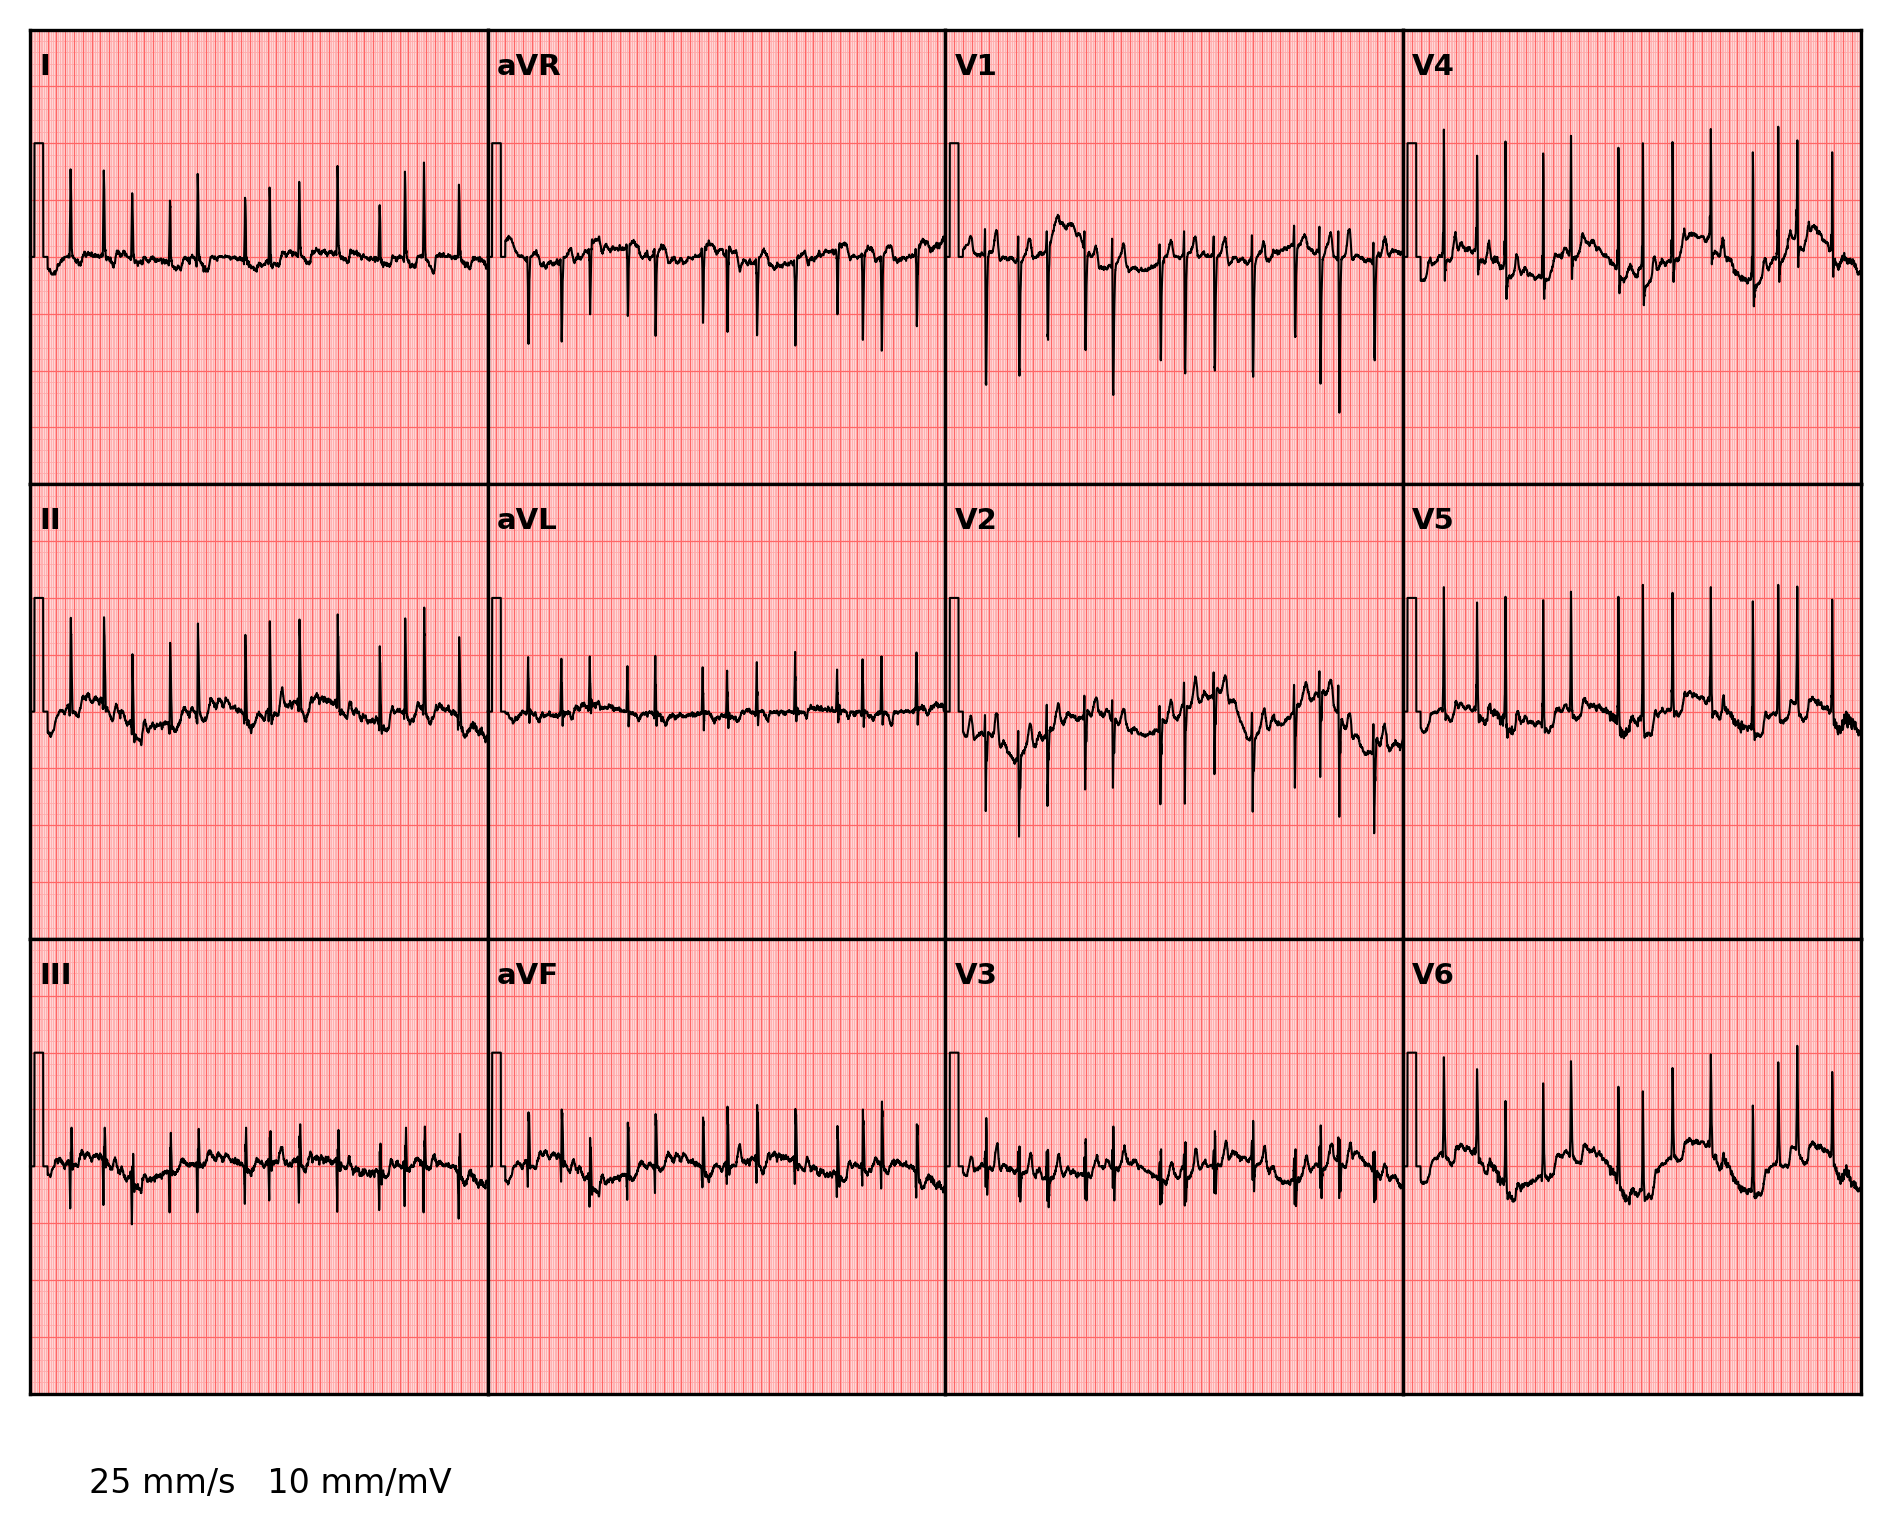

In [5]:
# Draw — sampling_rate from MetaData; fall back to 500 if unavailable
samplefreq = (reader.MetaData.get('sampling frequency (processed)') or 500)
style = ECGStyle(figsize=(20 * CM_TO_IN, 15 * CM_TO_IN), dpi=300)
drawing = ECGDrawing()(
    reader,
    mapper=mapper,
    style=style,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    show_cal_pulse=True,
)
fig = drawing.figure
# #### speed / gain annotation
fig.text(
    0.15, 0.05,
    "25 mm/s   10 mm/mV",
    fontsize=8, va='bottom', ha='left',
    transform=fig.transFigure,
)
plt.show()

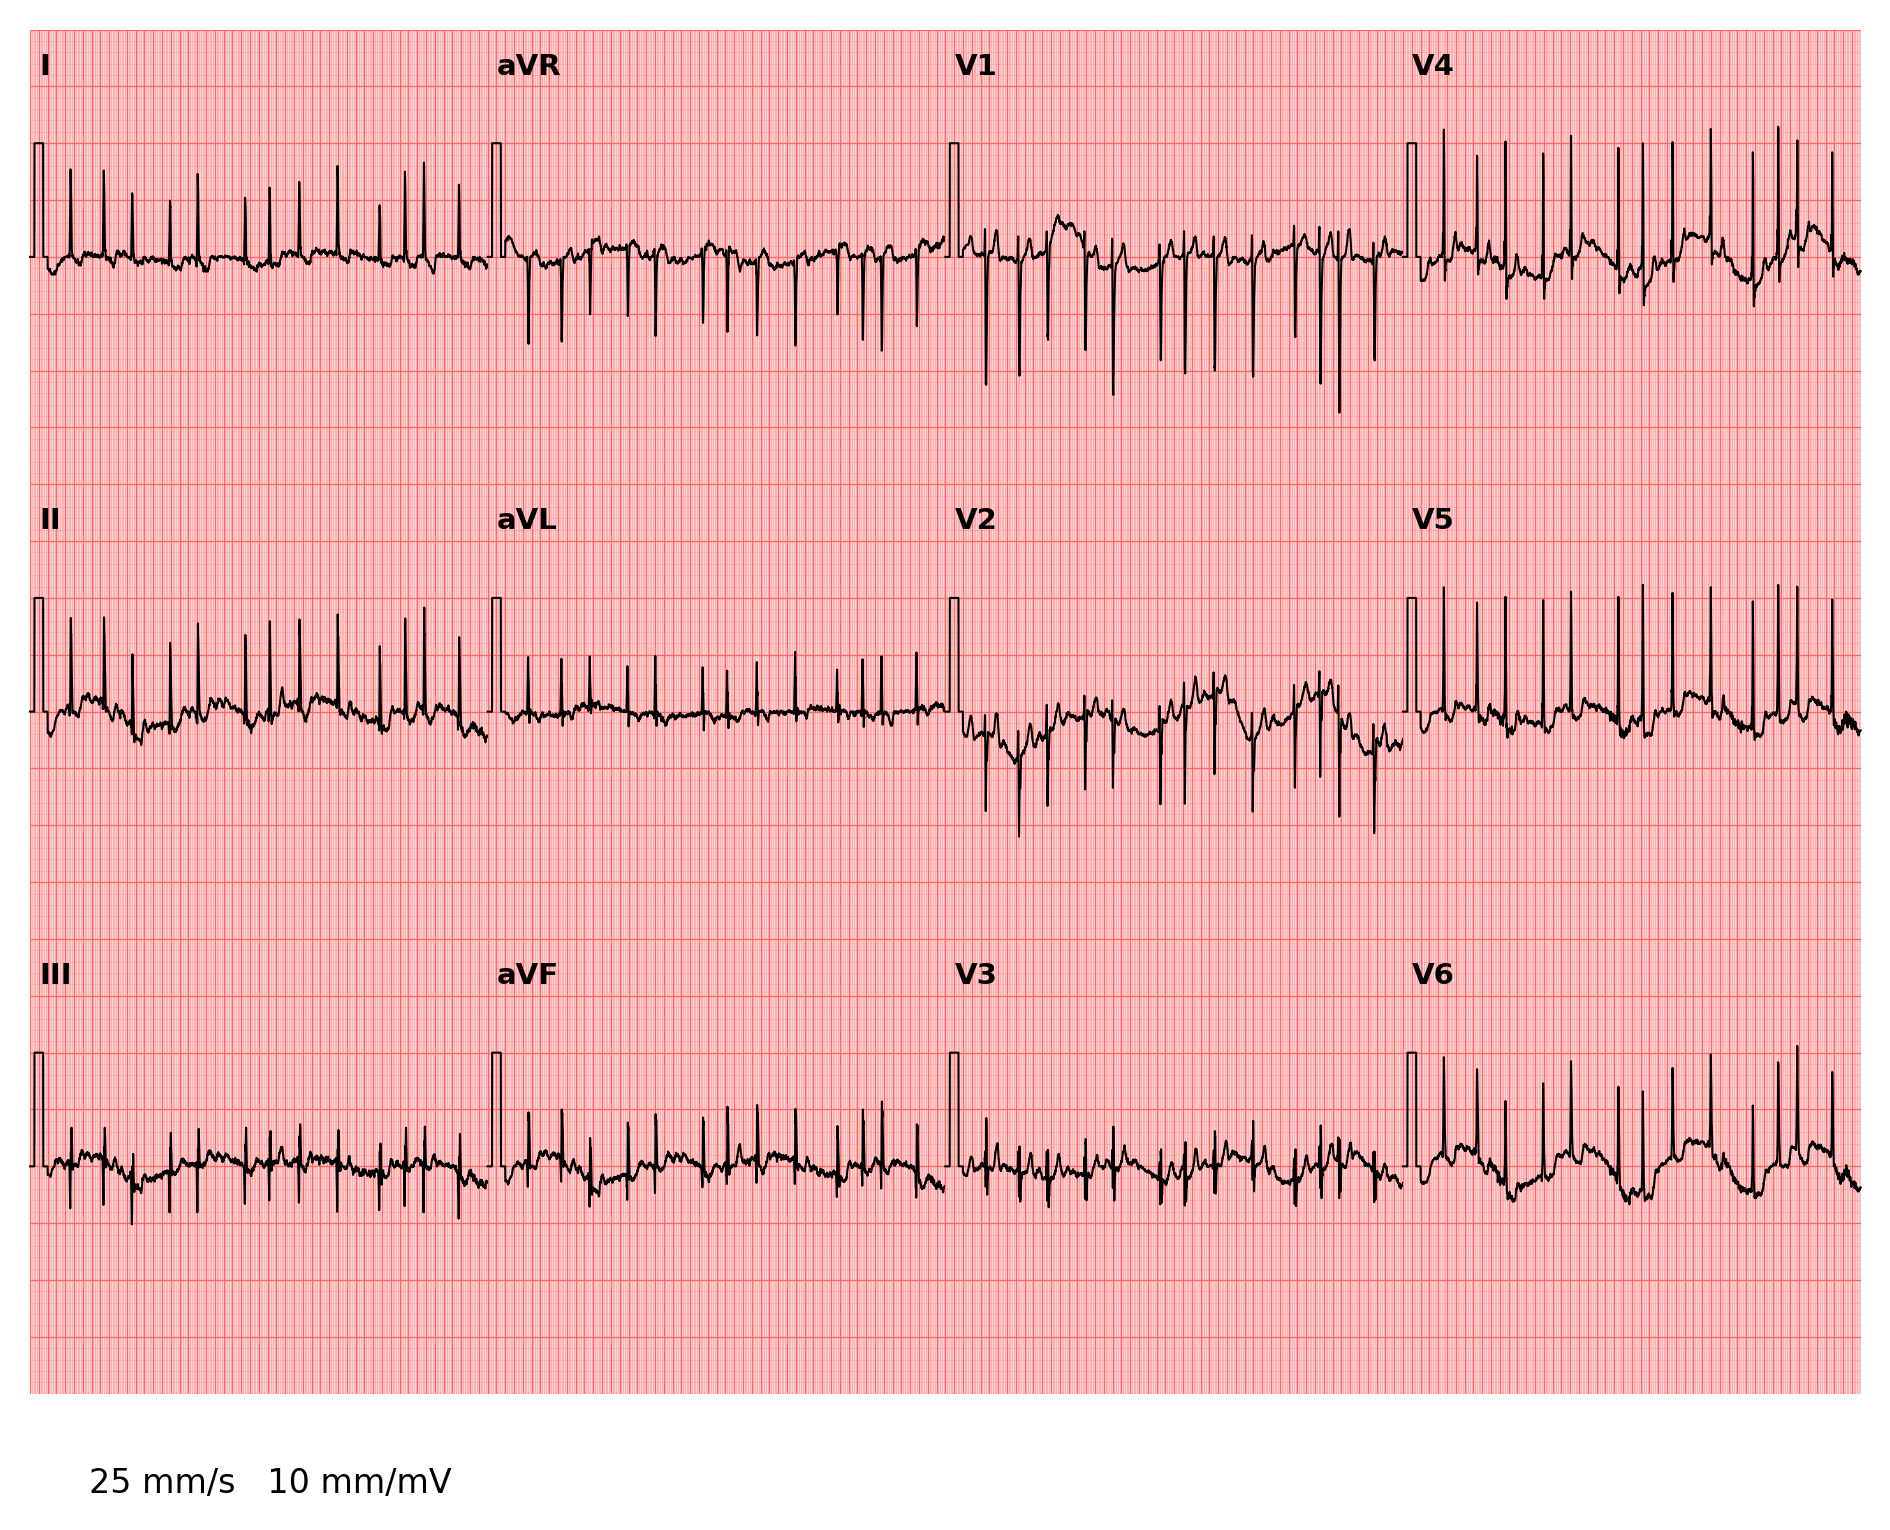

In [6]:
# #### canonical ECG — no panel borders (clinical paper look)
# Same parameters as the cell above; spine removal added.
drawing_ns = ECGDrawing()(
    reader,
    mapper=mapper,
    style=style,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    show_cal_pulse=True,
)
fig_ns = drawing_ns.figure
fig_ns.text(
    0.15, 0.05,
    "25 mm/s   10 mm/mV",
    fontsize=8, va='bottom', ha='left',
    transform=fig_ns.transFigure,
)
for ax in drawing_ns.axes.values():
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Non-traditional layout: 3-lead monitoring strip

The `mapper` dict controls which leads appear and where. Passing only three
leads — I, II, III stacked in a single column — produces a compact monitoring
strip common in bedside telemetry displays.

Lead 'V1' is in signal data but not requested in mapper.
Lead 'V2' is in signal data but not requested in mapper.
Lead 'V3' is in signal data but not requested in mapper.
Lead 'V4' is in signal data but not requested in mapper.
Lead 'V5' is in signal data but not requested in mapper.
Lead 'V6' is in signal data but not requested in mapper.
Lead 'aVF' is in signal data but not requested in mapper.
Lead 'aVL' is in signal data but not requested in mapper.
Lead 'aVR' is in signal data but not requested in mapper.


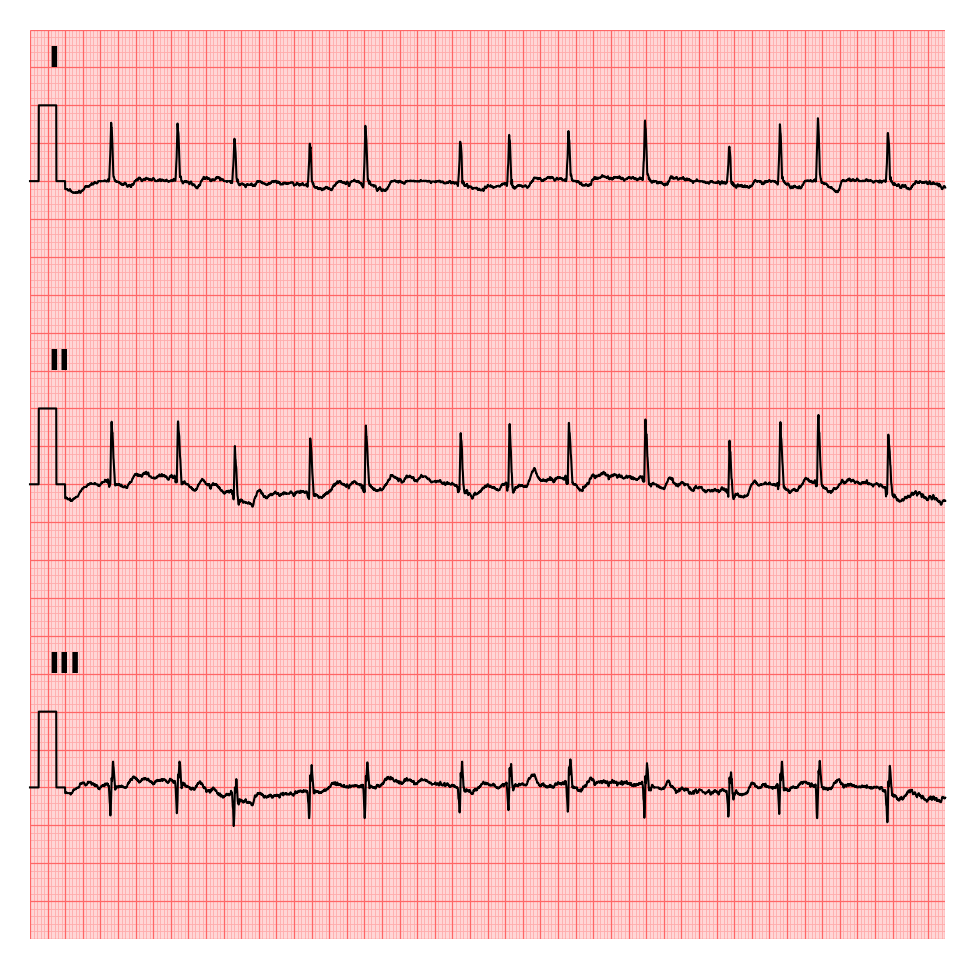

In [7]:
# #### 3-lead monitoring layout
mapper_3lead = {
    'I':   (0, slice(0, 1)),
    'II':  (1, slice(0, 1)),
    'III': (2, slice(0, 1)),
}
style_3lead = ECGStyle(figsize=(10 * CM_TO_IN, 10 * CM_TO_IN), dpi=300)
drawing_3lead = ECGDrawing()(
    reader,
    mapper=mapper_3lead,
    style=style_3lead,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    show_cal_pulse=True,
)
for ax in drawing_3lead.axes.values():
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Per-lead trace styling

Any `kwargs_*` parameter accepts either a flat dict (uniform across all leads)
or a dict-of-dicts (one entry per lead). Passing a dict-of-dicts lets you
style each lead independently.

Here the same 3-lead layout is redrawn with a different trace colour per lead.

Lead 'V1' is in signal data but not requested in mapper.
Lead 'V2' is in signal data but not requested in mapper.
Lead 'V3' is in signal data but not requested in mapper.
Lead 'V4' is in signal data but not requested in mapper.
Lead 'V5' is in signal data but not requested in mapper.
Lead 'V6' is in signal data but not requested in mapper.
Lead 'aVF' is in signal data but not requested in mapper.
Lead 'aVL' is in signal data but not requested in mapper.
Lead 'aVR' is in signal data but not requested in mapper.


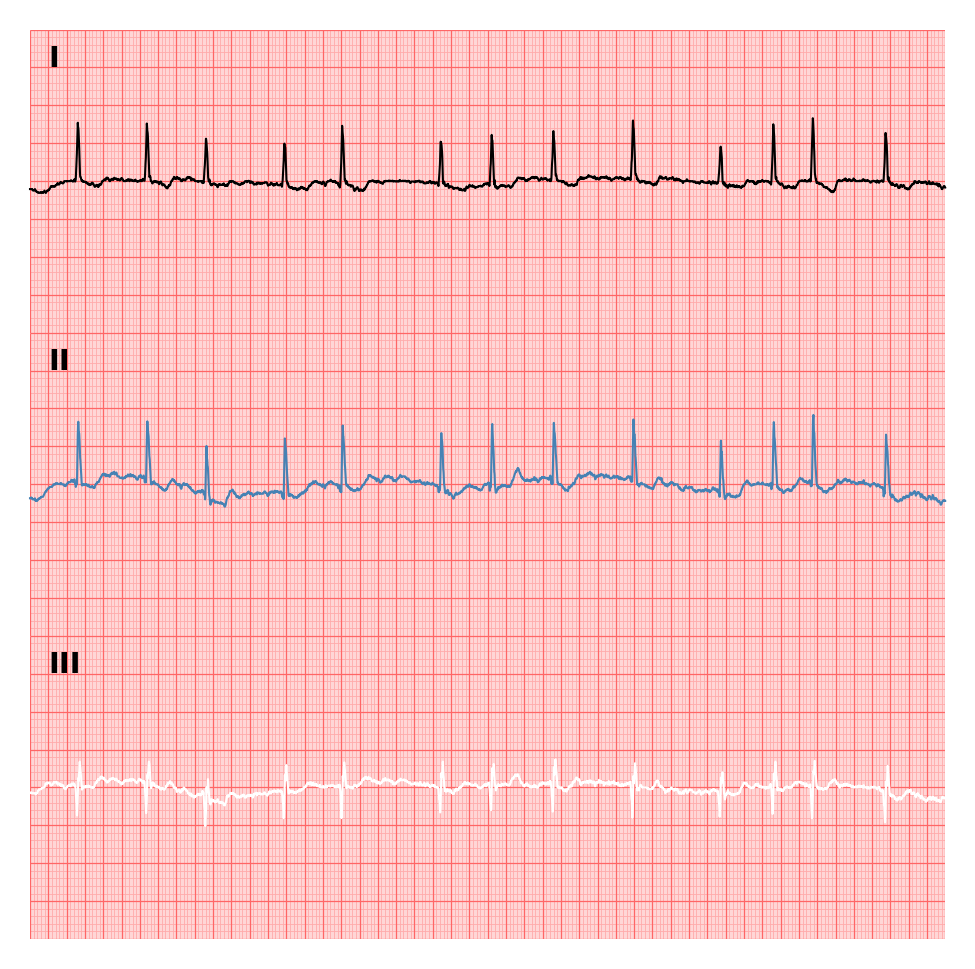

In [8]:
# #### per-lead trace colour: I=black, II=steelblue, III=firebrick
drawing_3lead_kw = ECGDrawing()(
    reader,
    mapper=mapper_3lead,
    style=style_3lead,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    show_cal_pulse=False,
    kwargs_plot={
        'I':   {'color': 'black'},
        'II':  {'color': 'steelblue'},
        'III': {'color': 'white'},
    },
)
for ax in drawing_3lead_kw.axes.values():
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Combined 12-lead with Lead II rhythm strip

A standard clinical printout shows the 12-lead grid followed immediately by a
full-width Lead II rhythm strip. Because `reader.WaveForms` is a plain dict, a
temporary key `'II_strip'` can be added to map Lead II to a second position
(row 3, spanning all 4 columns). The key is removed after drawing.

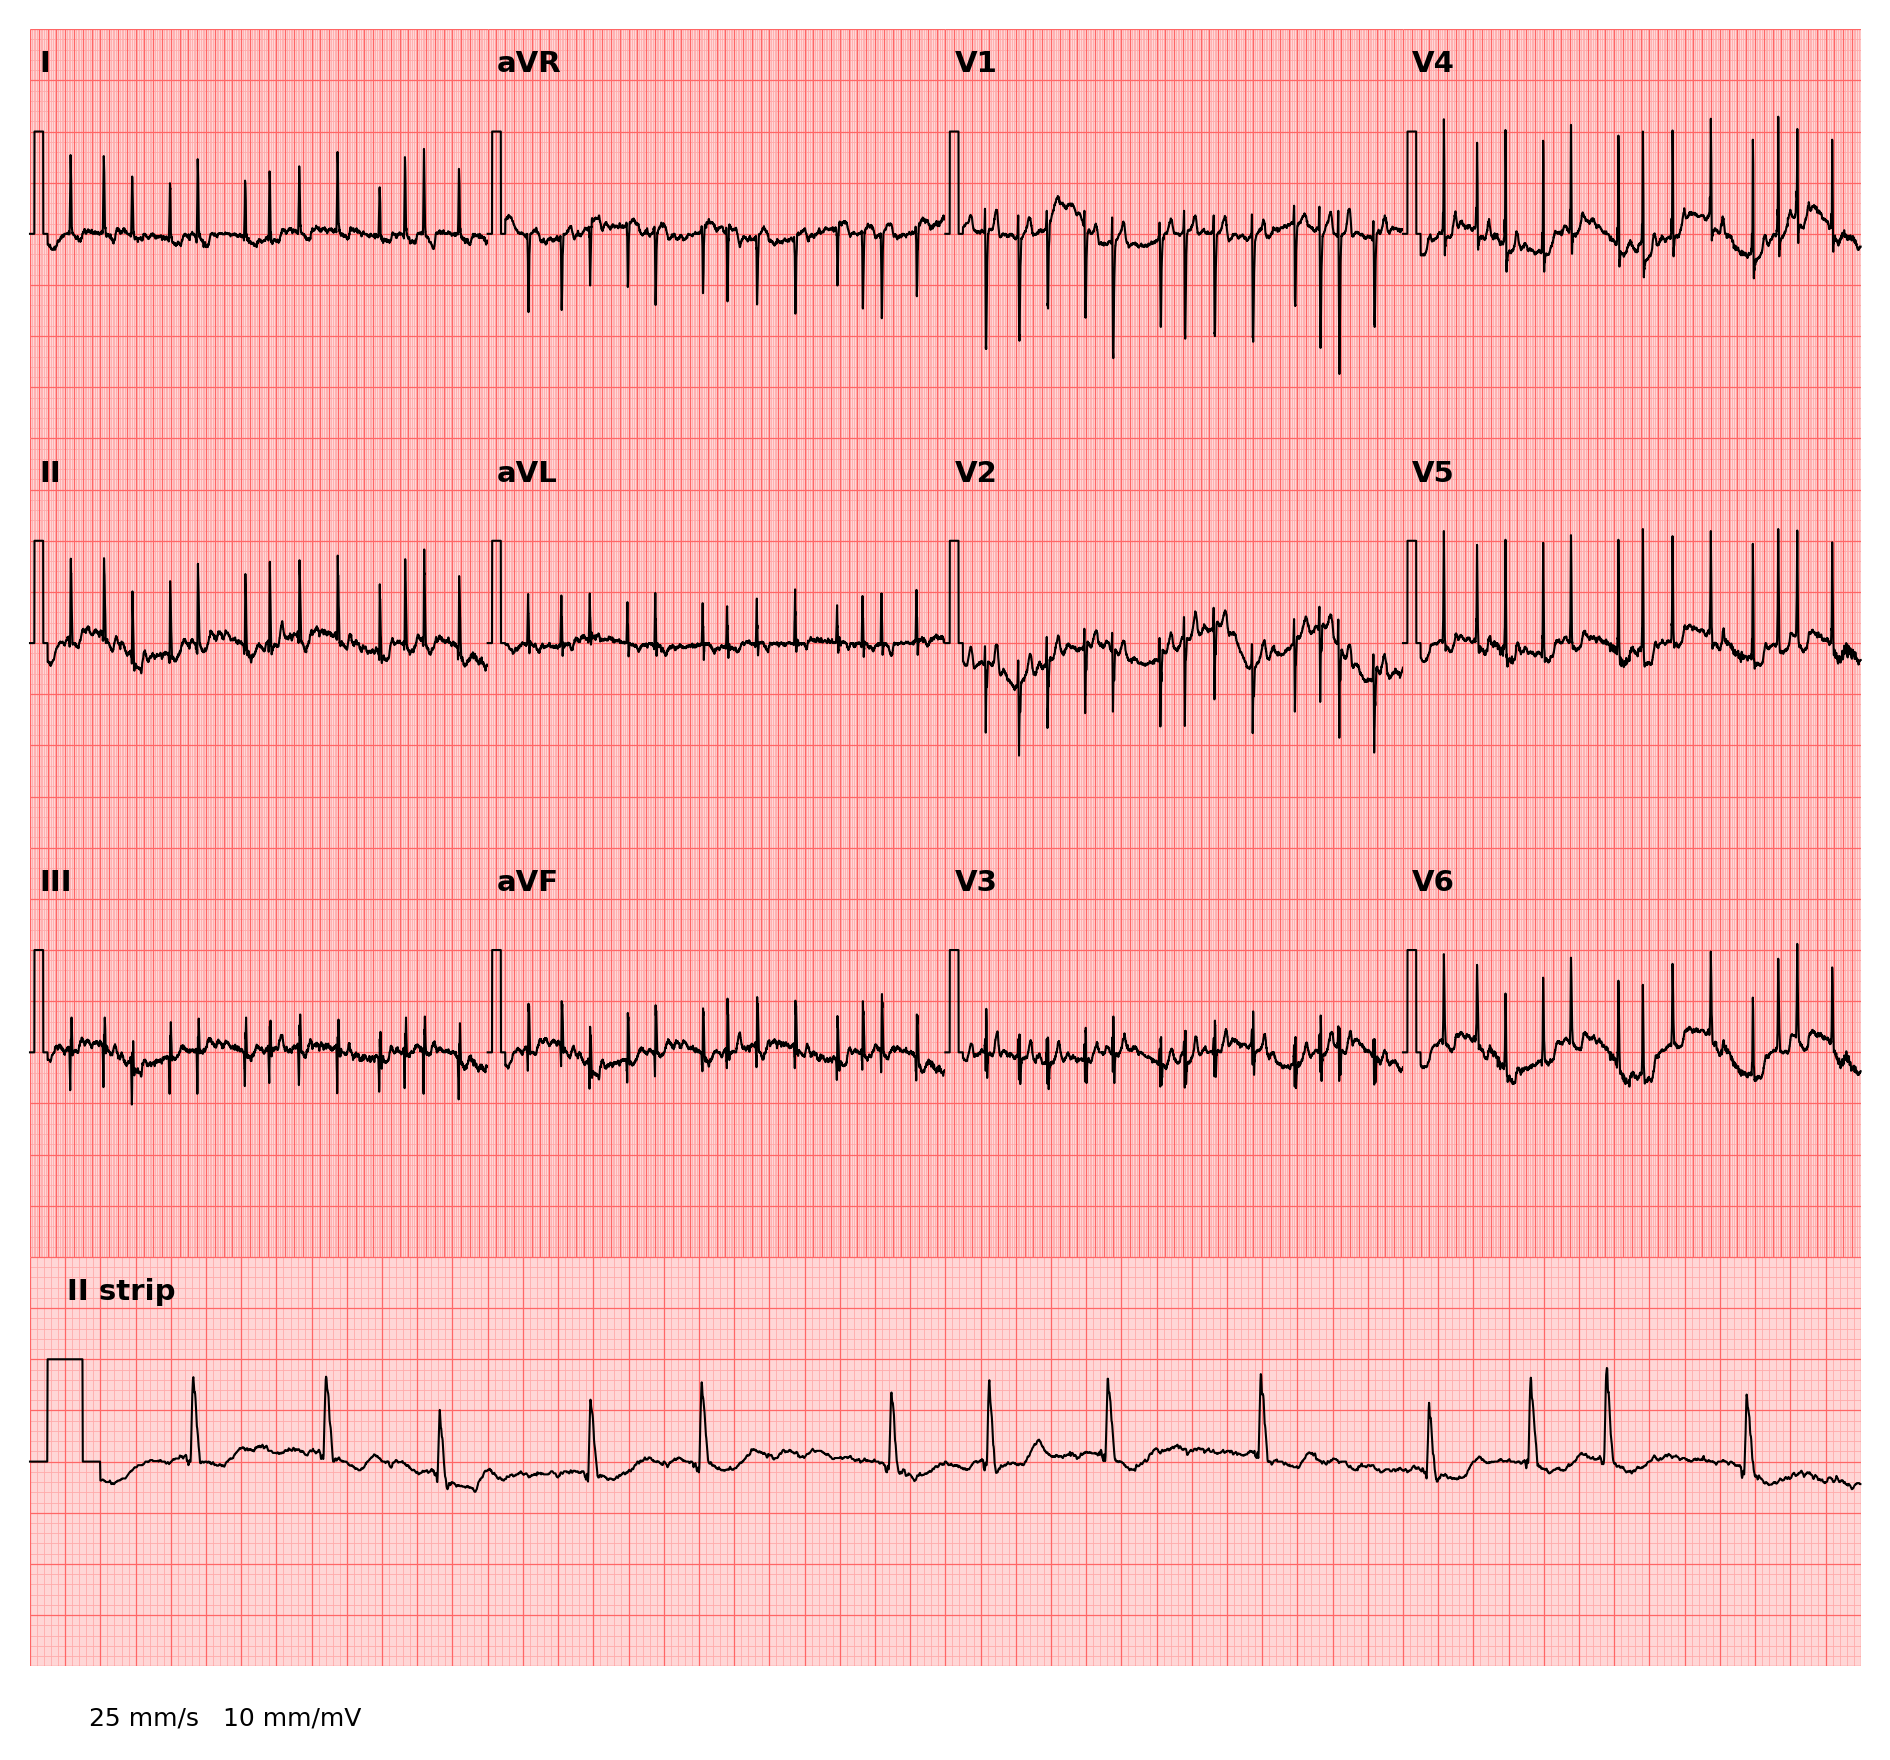

In [9]:
# #### extend mapper with a full-width Lead II rhythm strip at row 3
reader.WaveForms['II strip'] = reader.WaveForms['II']
mapper_rhythm = dict(mapper)
mapper_rhythm['II strip'] = (3, slice(0, 4))
style_rhythm = ECGStyle(figsize=(20 * CM_TO_IN, 18 * CM_TO_IN), dpi=300)
drawing_rhythm = ECGDrawing()(
    reader,
    mapper=mapper_rhythm,
    style=style_rhythm,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
    show_cal_pulse=True,
)
fig_r = drawing_rhythm.figure
fig_r.text(
    0.15, 0.08,
    "25 mm/s   10 mm/mV",
    fontsize=6, va='bottom', ha='left',
    transform=fig_r.transFigure,
)
# #### remove inter-panel borders
for ax in drawing_rhythm.axes.values():
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()
# #### clean up temporary key
del reader.WaveForms['II strip']

## Overplotting: clip_on_trace

`ECGStyle.clip_on_trace` controls whether signal traces are clipped at panel
boundaries. The default (`False`) allows large deflections (e.g. tall R-waves
or deep aVL Q-waves) to cross into adjacent panels, replicating the look of
physical ECG paper. Setting `clip_on_trace=True` clips traces to each panel.

The demo scales aVL ×5 to make the difference visible.

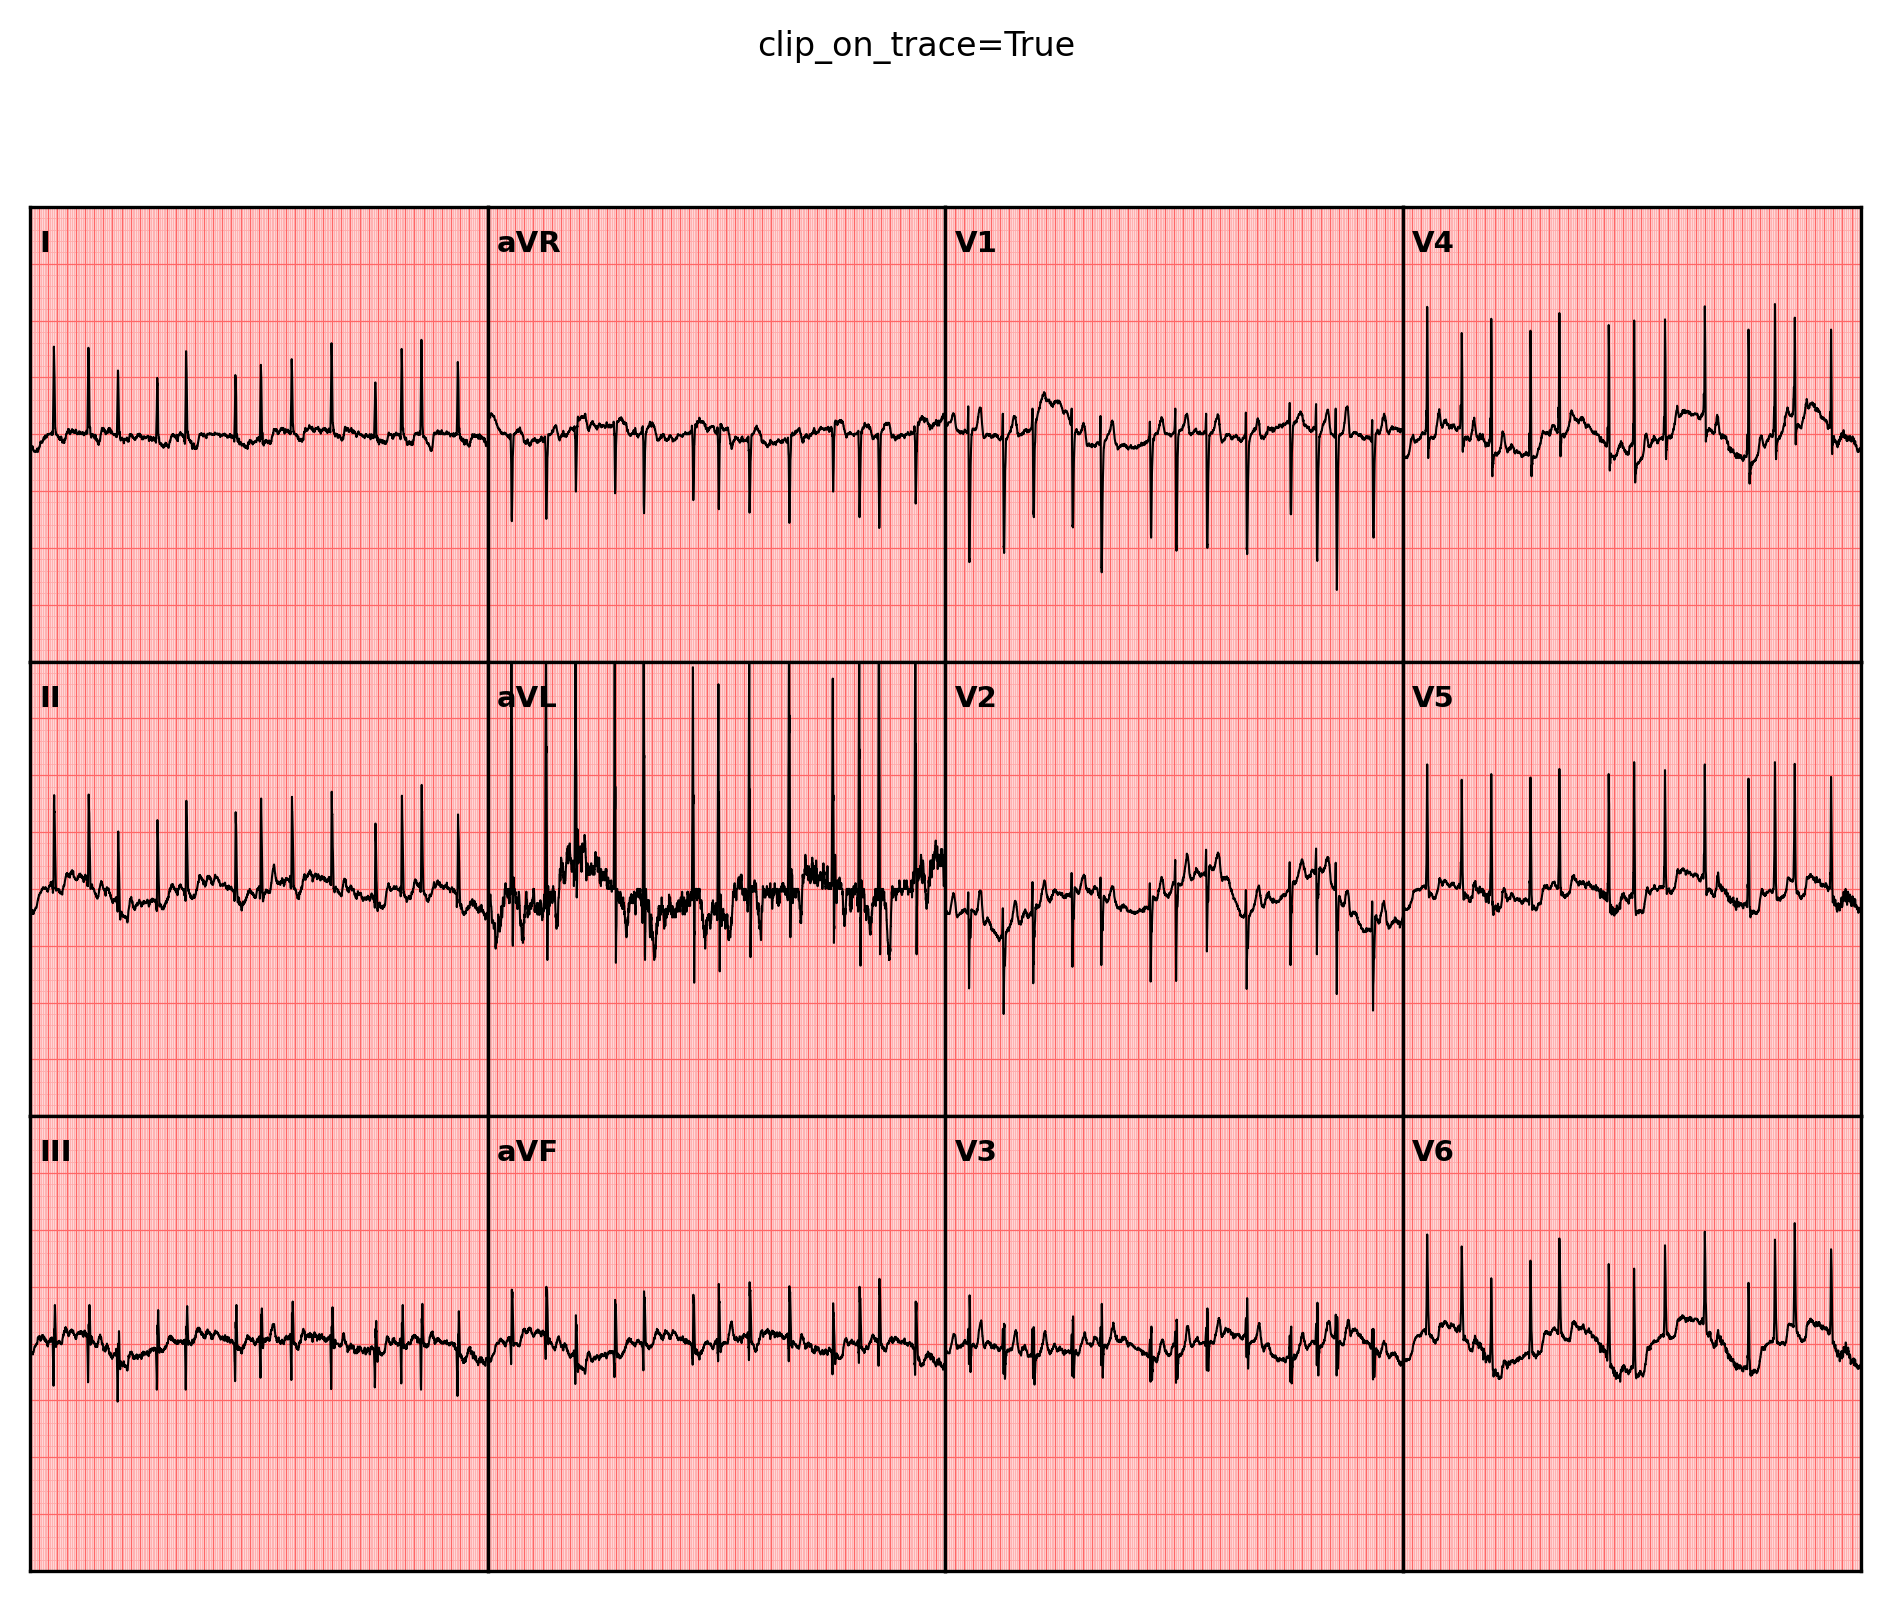

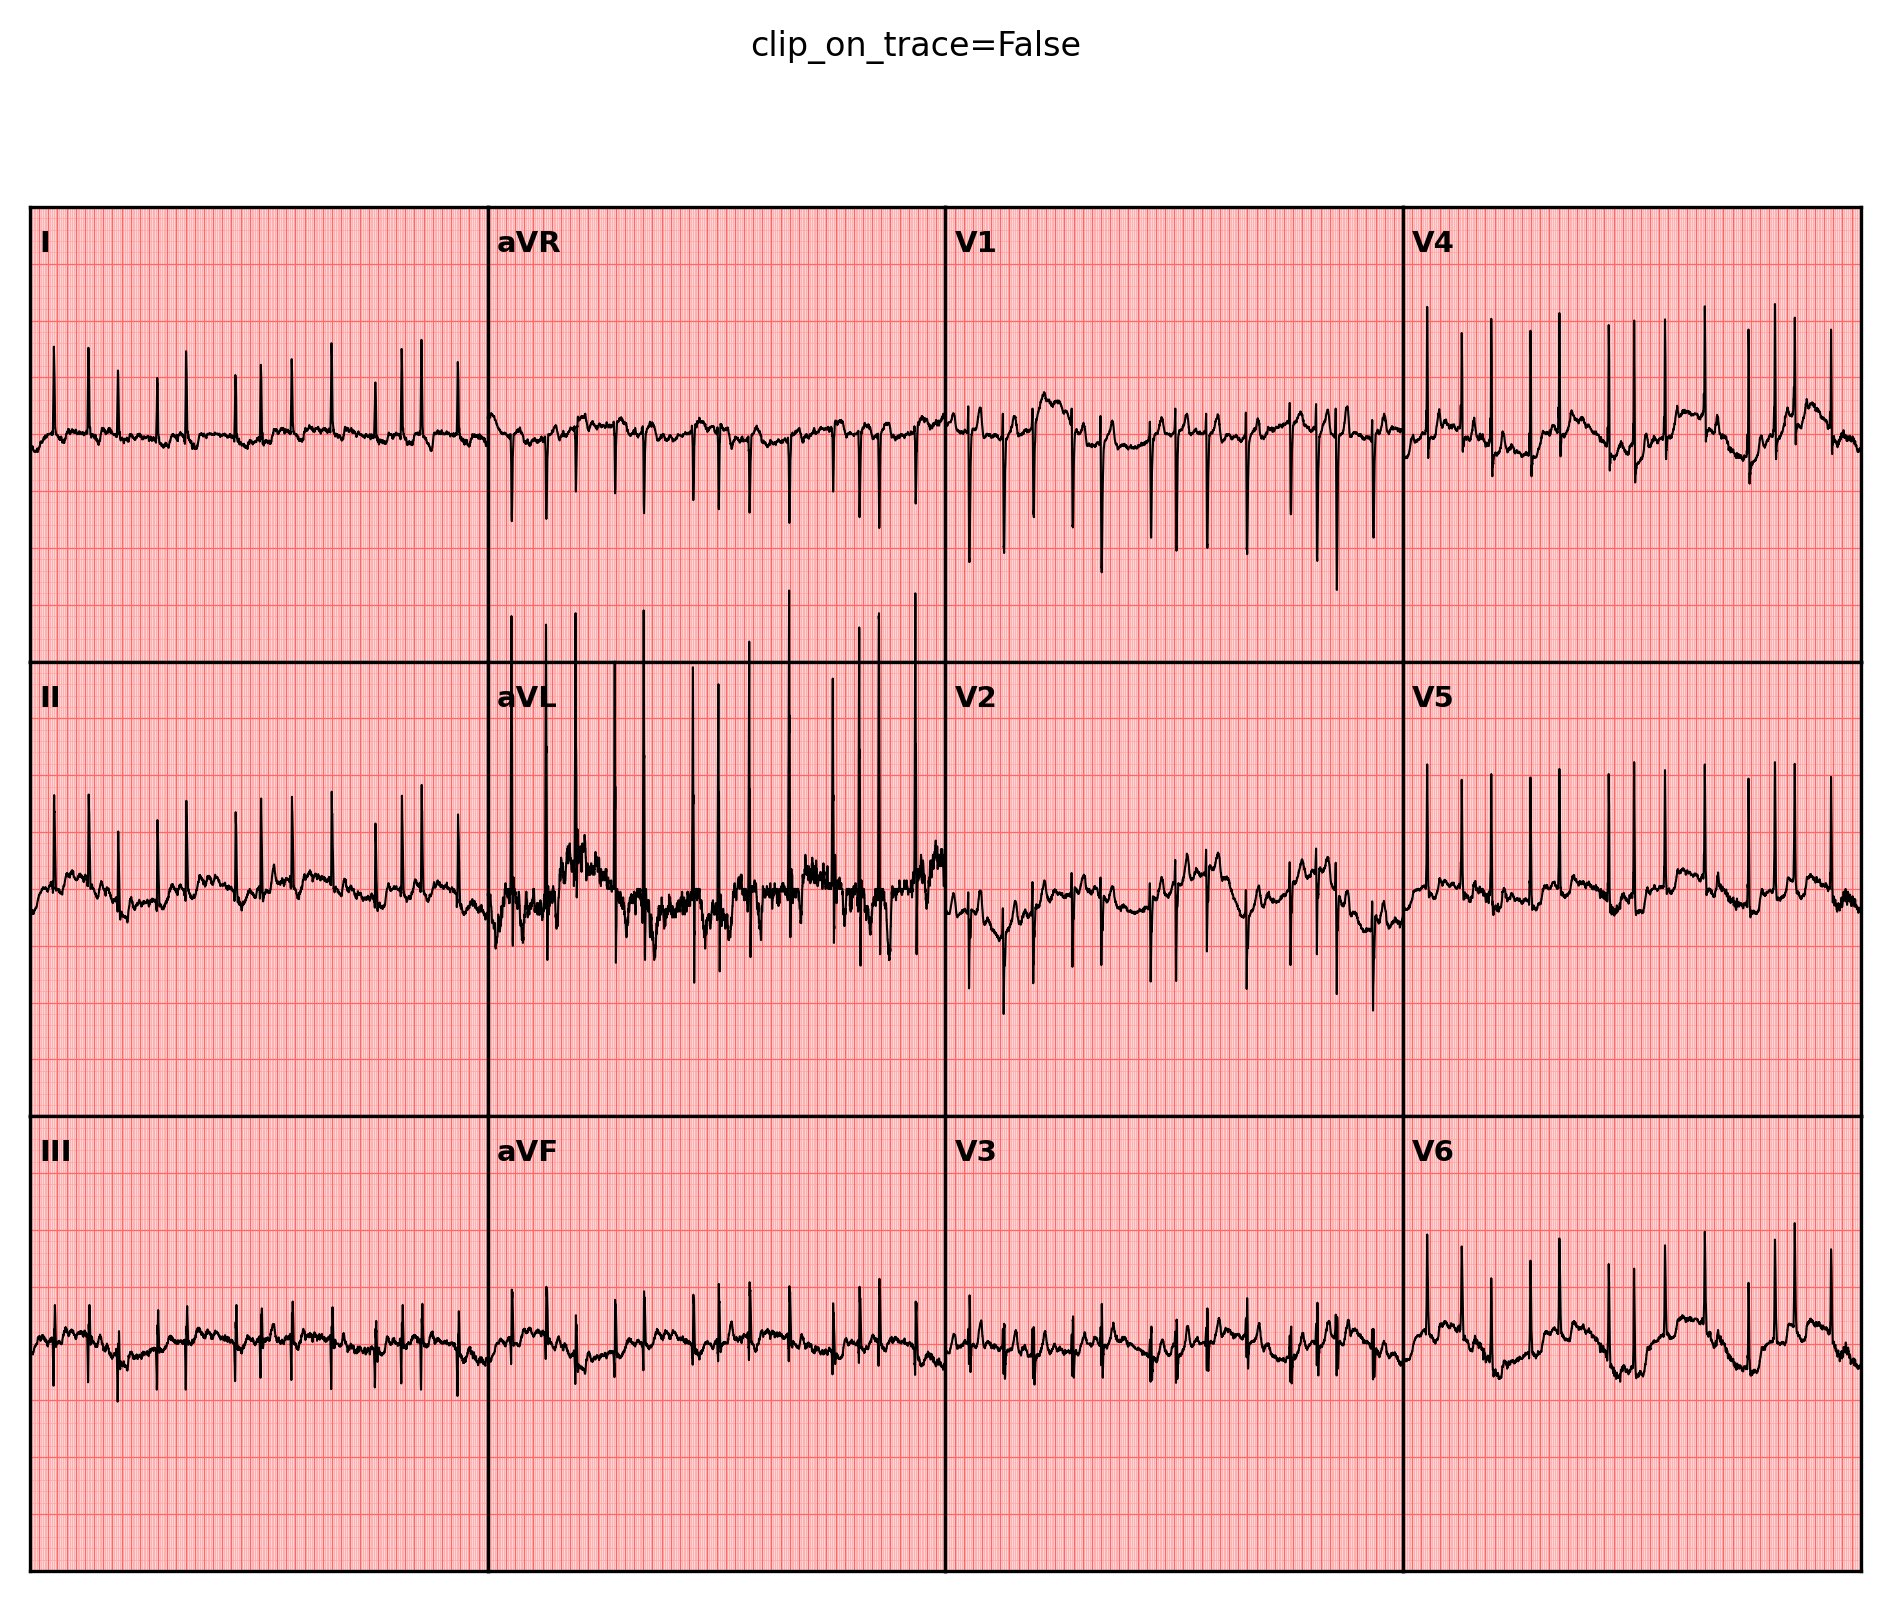

In [10]:
# #### temporarily exaggerate aVL to make clipping visible
_orig_aVL = reader.WaveForms['aVL']
reader.WaveForms['aVL'] = _orig_aVL * 5

style_on = ECGStyle(
    figsize=(20 * CM_TO_IN, 15 * CM_TO_IN), dpi=300, clip_on_trace=True
)
drawing_on = ECGDrawing()(
    reader, mapper=mapper, style=style_on,
    sampling_rate=samplefreq, show_axes=None,
    show_lead_labels=True, show_cal_pulse=False,
)
drawing_on.figure.suptitle("clip_on_trace=True", fontsize=8)
plt.show()

style_off = ECGStyle(
    figsize=(20 * CM_TO_IN, 15 * CM_TO_IN), dpi=300, clip_on_trace=False
)
drawing_off = ECGDrawing()(
    reader, mapper=mapper, style=style_off,
    sampling_rate=samplefreq, show_axes=None,
    show_lead_labels=True, show_cal_pulse=False,
)
drawing_off.figure.suptitle("clip_on_trace=False", fontsize=8)
plt.show()

# #### restore original amplitude
reader.WaveForms['aVL'] = _orig_aVL

## Research figure: limb-leads subset

`ECGStyle.hspace` and `wspace` control panel separation (default `0.0` mimics
continuous ECG paper). Increasing them and keeping spines visible produces a
style suited to research figures or clinical reports. Here the six limb leads
are arranged in a 2-row × 3-column grid with both axes displayed.

Lead 'V1' is in signal data but not requested in mapper.
Lead 'V2' is in signal data but not requested in mapper.
Lead 'V3' is in signal data but not requested in mapper.
Lead 'V4' is in signal data but not requested in mapper.
Lead 'V5' is in signal data but not requested in mapper.
Lead 'V6' is in signal data but not requested in mapper.


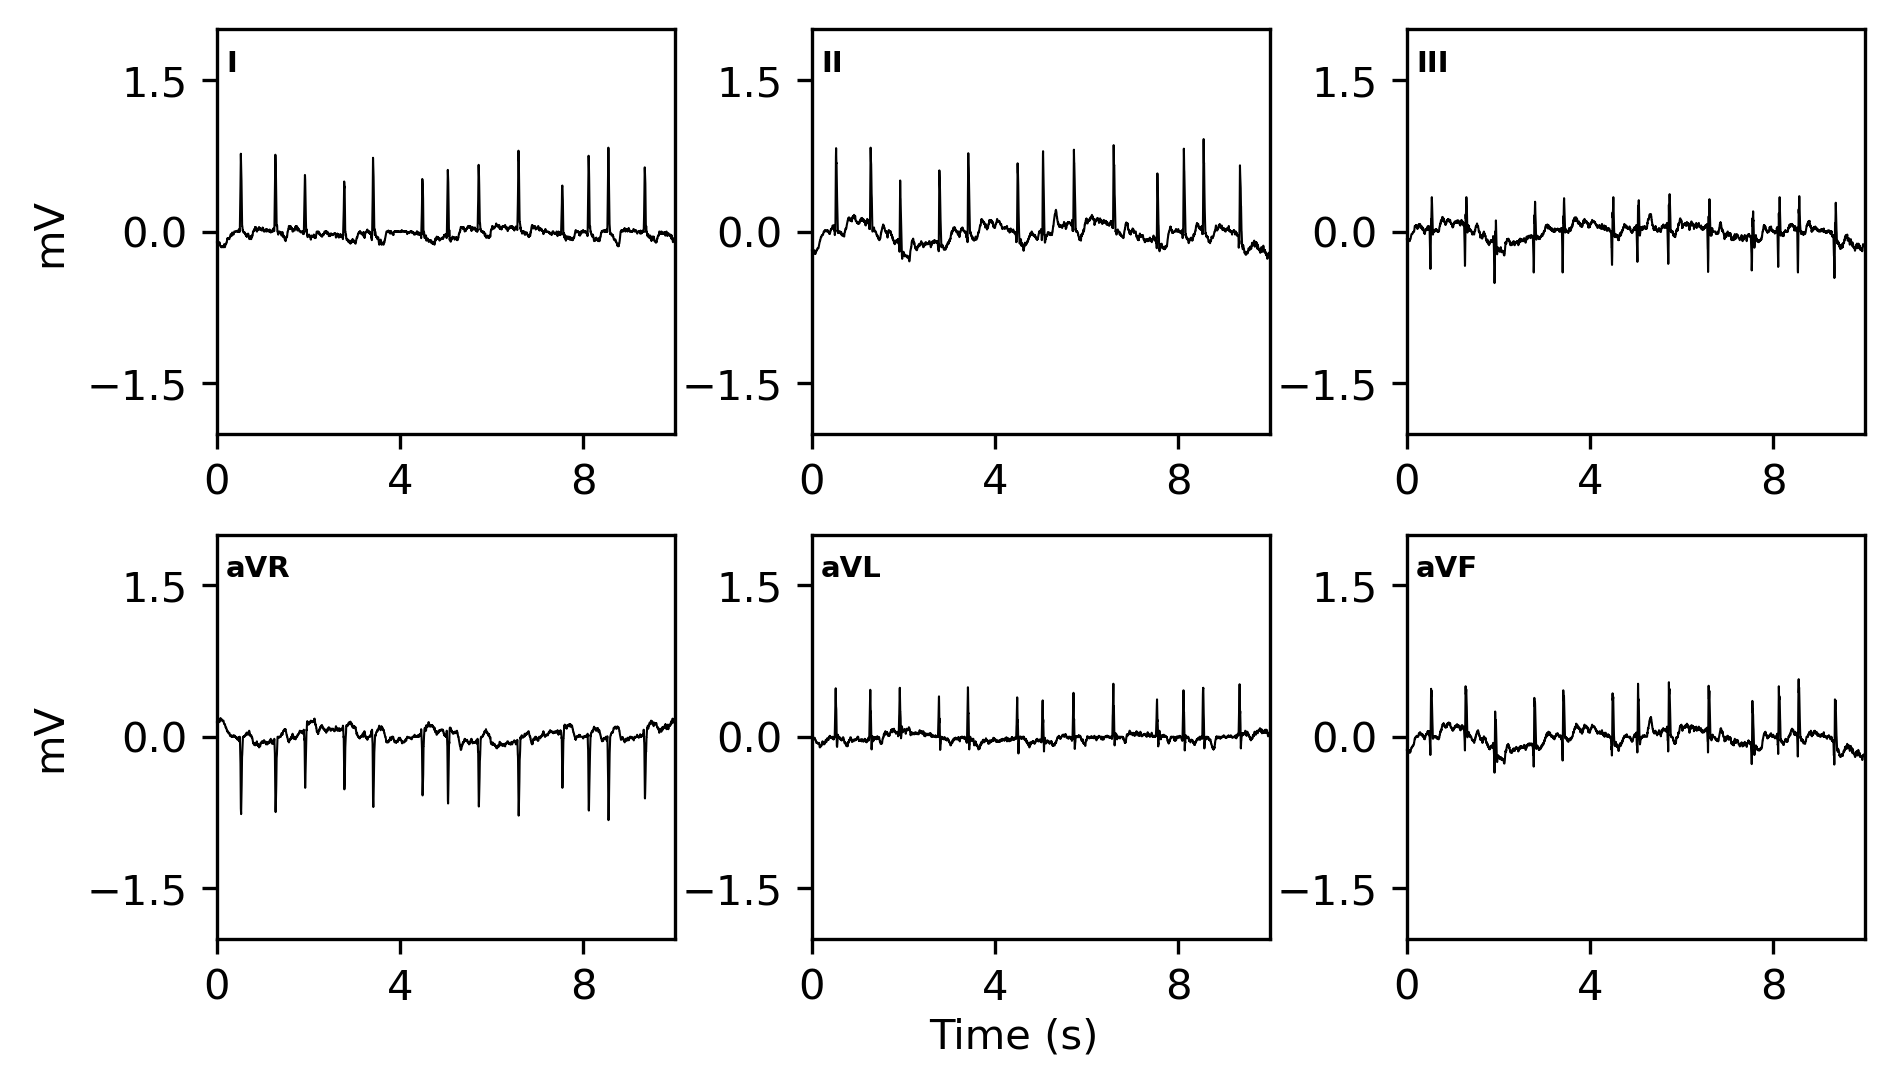

In [11]:
from matplotlib.ticker import MaxNLocator

# #### limb leads, 2×3 grid, separated panels, spines visible
limb_leads = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF']
mapper_limb = {
    lead: (row, slice(col, col + 1))
    for i, lead in enumerate(limb_leads)
    for row, col in [divmod(i, 3)]
}
style_research = ECGStyle(
    figsize=(18 * CM_TO_IN, 10 * CM_TO_IN),
    dpi=300,
    hspace=0.25,
    wspace=0.30,
    # turning off the grid
    major_grid_linewidth=0.0,
    minor_grid_linewidth=0.0,
    background_color='white',
)
drawing_research = ECGDrawing()(
    reader,
    mapper=mapper_limb,
    style=style_research,
    sampling_rate=samplefreq,
    show_axes='b',
    show_lead_labels=True,
    show_cal_pulse=False,
)
# #### reduce tick density to prevent label overplotting
for ax in drawing_research.axes.values():
    ax.xaxis.set_major_locator(MaxNLocator(nbins=3, prune='upper'))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3, prune='both'))
    ax.set_xlim(left=0)
# #### y-axis label on leftmost panels only
drawing_research.axes['I'].set_ylabel('mV', fontsize=10)
drawing_research.axes['aVR'].set_ylabel('mV', fontsize=10)
# #### single x-axis label below the figure
fig_research = drawing_research.figure
fig_research.supxlabel('Time (s)', fontsize=10, y=0.01)
# Spines intentionally kept — research-figure style
plt.show()

### Median beats

Median beats are stored in `reader.MedianBeats` and rendered by passing
`source='median'` to `ECGDrawing`. The mapper is built the same way — one
panel per lead with data.

Median beat leads: ['I', 'II', 'III', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'aVF', 'aVL', 'aVR']




In [12]:
available_mb = [k for k, v in reader.MedianBeats.items() if v is not None]
print("Median beat leads:", available_mb)

mapper_mb = {
    lead: (i, slice(0, 1))
    for i, lead in enumerate(available_mb)
}

# Median beats are 600 samples at 500 Hz (1.2 s total).
# Set the window to capture the full P-QRS-T complex.
style_mb = ECGStyle(
    figsize=(6, len(available_mb) * 2),
    x_lim=(0.4, 0.6),
    clip_on_trace=True,
)
drawing_mb = ECGDrawing()(
    reader,
    mapper=mapper_mb,
    source='median',
    style=style_mb,
    sampling_rate=samplefreq,
    show_axes=None,
    show_lead_labels=True,
)
plt.show()

## Map figure to numpy array

`to_numpy()` renders an `ECGDrawing` figure to a `(height, width, 4)` uint8
RGBA array. This is useful for embedding ECG images in composite figures or
passing them directly to machine-learning pipelines. Pass `close=False` to
keep the underlying matplotlib figure open for further inspection.

In [13]:
# #### render two drawings to numpy arrays
arr_clinical = drawing.to_numpy(close=False)           # canonical 12-lead
arr_research = drawing_research.to_numpy(close=False)  # limb-leads subset
print(f"clinical  shape={arr_clinical.shape}  dtype={arr_clinical.dtype}")
print(f"research  shape={arr_research.shape}  dtype={arr_research.dtype}")

clinical  shape=(1771, 2362, 4)  dtype=uint8
research  shape=(1181, 2125, 4)  dtype=uint8


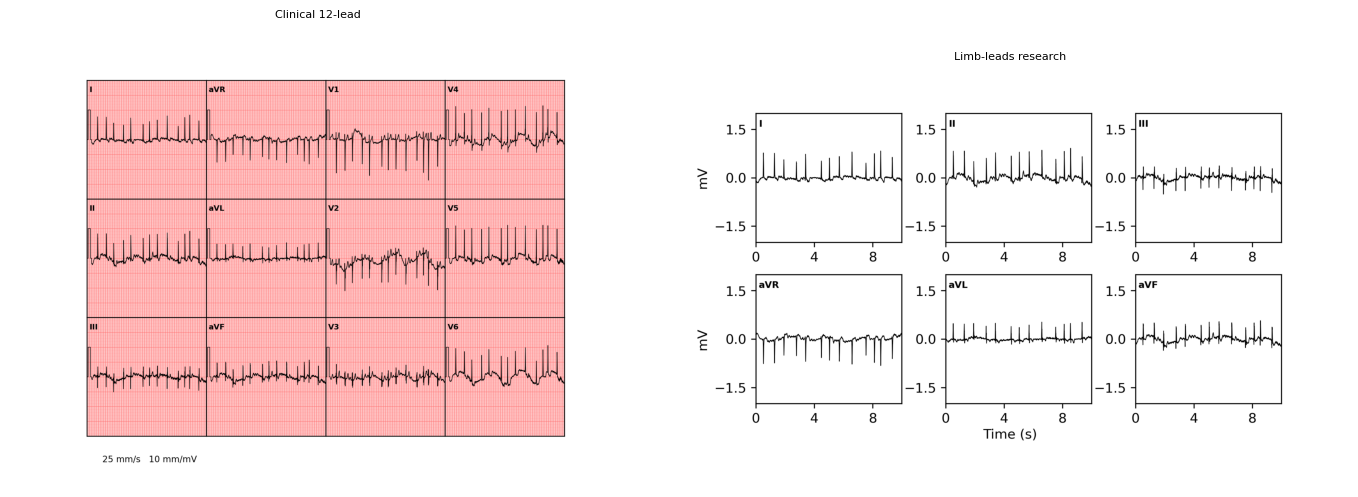

In [14]:
# #### embed ECG images in a composite matplotlib figure
fig_comp, axes_comp = plt.subplots(1, 2, figsize=(14, 5))
axes_comp[0].imshow(arr_clinical)
axes_comp[0].set_title("Clinical 12-lead", fontsize=8)
axes_comp[0].axis('off')
axes_comp[1].imshow(arr_research)
axes_comp[1].set_title("Limb-leads research", fontsize=8)
axes_comp[1].axis('off')
fig_comp.tight_layout()
plt.show()

### Utility for machine learning

`to_numpy()` converts any ECG figure to a `(H, W, 4)` uint8 RGBA array.
Slicing to RGB (`arr[..., :3]`) or converting to grayscale yields a direct
input tensor for standard convolutional classifiers — for example arrhythmia
detection or rhythm classification models. The approach treats the rendered ECG
image as the input representation, which is useful when pre-trained image models
are available and raw-signal models are not. Be aware that DPI, figsize, and
rendering parameters all become implicit hyperparameters of the pipeline.